# Aggregate Production Planning: Fixed Workforce Model

##### Tools: Python, PuLP (linear programming), pandas, matplotlib

### 1. Business problem

A manufacturer must plan production over a 6-period horizon to meet known demand at minimum total cost. The workforce size is fixed, so capacity in each period is limited to the available regular-time man-hours, which can be topped up with a limited amount of overtime man-hours at a higher wage. Units that are produced early and not sold are carried as inventory, which incurs a holding cost.

The planner must decide, for every period:

- how many units to produce,
- how many regular-time and overtime hours to use,
- how much inventory to carry to the next period,

so that demand is met every period (no backorders) at the lowest total cost.

> Source: this is a classic textbook-style aggregate production planning (APP) exercise. The extensions in sections 6-8 (cost breakdown, sensitivity analysis and scenario comparison) are my own additions.

### 2. Assumptions

- Each unit requires 1 man-hour of labor, so units produced = regular hours + overtime hours.
- Opening inventory is 3 units; there is no required ending inventory.
- No backorders: all demand in a period must be met from production and inventory.
- Holding cost is charged on ending inventory of each period.
- Workforce is fixed: regular labor is paid for all available regular hours, used or not, so that cost is a constant. Overtime is paid only for hours actually worked.
- Production is modeled as continuous (LP). The optimal solution turns out to be whole numbers, checked in section 5.

### 3. Mathematical formulation

##### (period t = 1,…,6)

Decision variables (all ≥ 0):  
Xt : units produced,  
It : ending inventory,  
Rt : regular hours used,  
Ot : overtime hours used

Constraints:
It−1 + Xt − It = Dt ∀ t :inventory balance,

Xt - Rt - Ot = 0 ∀ t :1 hour per unit,

Rt ≤ Rtmax,

Ot ≤ Otmax ∀ t :labor capacity

### 4. Data and model

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pulp import LpProblem, LpMinimize, LpVariable, lpSum, LpStatus, value, PULP_CBC_CMD

pd.options.display.float_format = "{:,.1f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
I0 = 3  # opening inventory (units)

data = pd.DataFrame(
    {
        "demand": [100, 100, 150, 200, 150, 100],        # units
        "unit_prod_cost": [7, 8, 8, 8, 7, 8],            # $ per unit, excluding labor
        "unit_hold_cost": [3, 4, 4, 4, 3, 2],            # $ per unit of ending inventory
        "reg_cost": [15, 15, 18, 18, 15, 15],            # $ per regular man-hour
        "ot_cost": [22.5, 22.5, 27, 27, 22.5, 22.5],     # $ per overtime man-hour
        "reg_hours": [120, 130, 120, 150, 100, 100],     # available regular man-hours
        "ot_hours": [30, 40, 40, 30, 30, 30],            # available overtime man-hours
    },
    index=pd.RangeIndex(1, 7, name="period"),
)
data


,demand,unit_prod_cost,unit_hold_cost,reg_cost,ot_cost,reg_hours,ot_hours
period,,,,,,,
1,100,7,3,15,22.5,120,30
2,100,8,4,15,22.5,130,40
3,150,8,4,18,27.0,120,40
4,200,8,4,18,27.0,150,30
5,150,7,3,15,22.5,100,30
6,100,8,2,15,22.5,100,30


In [8]:
def solve_app(df, opening_inventory=I0):
    # Build and solve the fixed-workforce APP model for the data frame `df`.
    T = list(df.index)
    prob = LpProblem("APP_Fixed_Workforce", LpMinimize)

    X = LpVariable.dicts("produce", T, lowBound=0)
    I = LpVariable.dicts("inventory", T, lowBound=0)
    R = LpVariable.dicts("reg_hours", T, lowBound=0)
    O = LpVariable.dicts("ot_hours", T, lowBound=0)

    fixed_payroll = sum(df.reg_cost[t] * df.reg_hours[t] for t in T)
    prob += (
        lpSum(df.unit_prod_cost[t] * X[t] + df.unit_hold_cost[t] * I[t] + df.ot_cost[t] * O[t] for t in T)
        + fixed_payroll
    )

    for t in T:
        prev = opening_inventory if t == T[0] else I[t - 1]
        prob += prev + X[t] - I[t] == df.demand[t], f"balance_{t}"
        prob += X[t] == R[t] + O[t], f"hours_{t}"
        prob += R[t] <= df.reg_hours[t], f"reg_cap_{t}"
        prob += O[t] <= df.ot_hours[t], f"ot_cap_{t}"

    prob.solve(PULP_CBC_CMD(msg=0))
    status = LpStatus[prob.status]
    if status != "Optimal":
        return prob, status, None

    plan = pd.DataFrame(
        {
            "demand": df.demand,
            "production": [X[t].value() for t in T],
            "ending_inventory": [I[t].value() for t in T],
            "regular_hours": [R[t].value() for t in T],
            "overtime_hours": [O[t].value() for t in T],
        },
        index=df.index,
    )
    plan["production_cost"] = plan.production * df.unit_prod_cost
    plan["holding_cost"] = plan.ending_inventory * df.unit_hold_cost
    plan["regular_labor_cost"] = df.reg_cost * df.reg_hours  # fixed payroll
    plan["overtime_cost"] = plan.overtime_hours * df.ot_cost
    plan["total_cost"] = plan[["production_cost", "holding_cost", "regular_labor_cost", "overtime_cost"]].sum(axis=1)
    return prob, status, plan


prob, status, plan = solve_app(data)
print("Solution status:", status)
print(f"Total production plan cost: ${value(prob.objective):,.2f}")

Solution status: Optimal
Total production plan cost: $20,192.50


### 5. Optimal plan and model checks

In [17]:
plan[["demand", "production", "ending_inventory", "regular_hours", "overtime_hours"]]

,demand,production,ending_inventory,regular_hours,overtime_hours
period,,,,,
1,100,120.0,23.0,120.0,0.0
2,100,147.0,70.0,130.0,17.0
3,150,120.0,40.0,120.0,0.0
4,200,180.0,20.0,150.0,30.0
5,150,130.0,0.0,100.0,30.0
6,100,100.0,0.0,100.0,0.0


In [9]:
# Sanity checks: the plan must satisfy the model's own rules

prev_inv = [I0] + list(plan.ending_inventory[:-1])

assert all(abs(p + x - i - dm) < 1e-6 for p, x, i, dm in zip(prev_inv, plan.production, plan.ending_inventory, plan.demand)), "inventory balance violated"
assert (plan.regular_hours <= data.reg_hours + 1e-6).all() and (plan.overtime_hours <= data.ot_hours + 1e-6).all(), "capacity violated"
assert abs(plan.total_cost.sum() - value(prob.objective)) < 1e-6, "cost breakdown does not match objective"
is_integer = ((plan[["production", "ending_inventory"]] % 1).abs() < 1e-6).all().all()

print("Plan satisfies balance and capacity constraints; cost breakdown reconciles with objective.")
print("Optimal plan is whole-number (no need for integer variables):", is_integer)

Plan satisfies balance and capacity constraints; cost breakdown reconciles with objective.
Optimal plan is whole-number (no need for integer variables): True


### 6. Visualising the plan

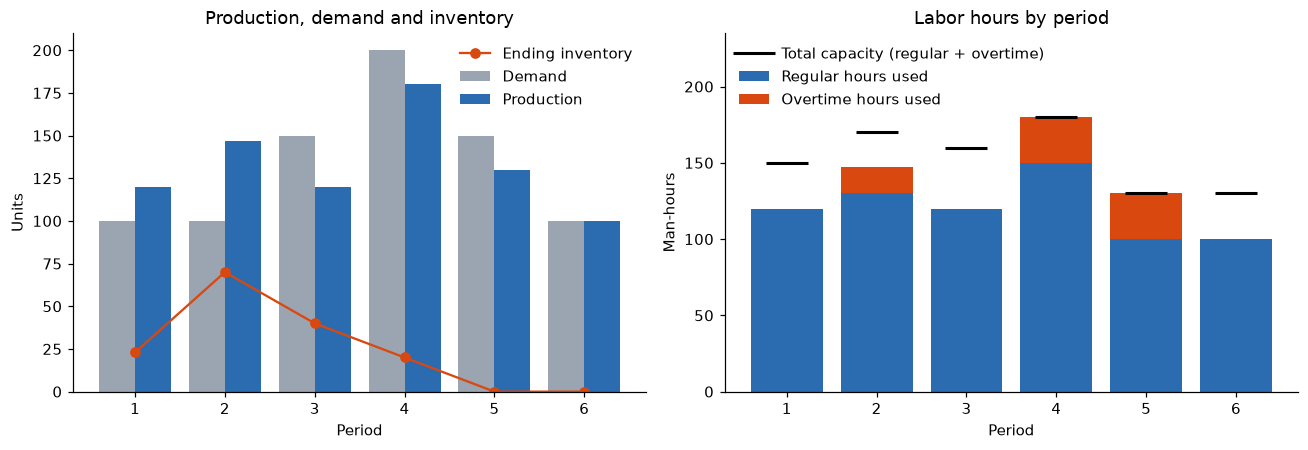

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: production vs demand, with inventory
ax = axes[0]
x = plan.index
ax.bar(x - 0.2, plan.demand, width=0.4, label="Demand", color="#9aa5b1")
ax.bar(x + 0.2, plan.production, width=0.4, label="Production", color="#2b6cb0")
ax.plot(x, plan.ending_inventory, color="#d9480f", marker="o", label="Ending inventory")
ax.set_title("Production, demand and inventory")
ax.set_xlabel("Period"); ax.set_ylabel("Units"); ax.legend(frameon=False)

# Right: labor used vs available
ax = axes[1]
ax.bar(x, plan.regular_hours, label="Regular hours used", color="#2b6cb0")
ax.bar(x, plan.overtime_hours, bottom=plan.regular_hours, label="Overtime hours used", color="#d9480f")
ax.plot(x, data.reg_hours + data.ot_hours, color="black", ls="", marker="_", ms=28, mew=2, label="Total capacity (regular + overtime)")
ax.set_title("Labor hours by period")
ax.set_ylim(0, 235)
ax.set_xlabel("Period"); ax.set_ylabel("Man-hours"); ax.legend(frameon=False, loc="upper left", ncol=1)

plt.tight_layout()
plt.show()

### 7. Cost breakdown

In [13]:
cost_cols = ["production_cost", "holding_cost", "regular_labor_cost", "overtime_cost"]
breakdown = plan[cost_cols].sum().rename("cost").to_frame()
breakdown["share_%"] = 100 * breakdown.cost / breakdown.cost.sum()
breakdown.loc["TOTAL"] = [breakdown.cost.sum(), 100.0]
breakdown

,cost,share_%
production_cost,"6,126.0",30.3
holding_cost,589.0,2.9
regular_labor_cost,"11,610.0",57.5
overtime_cost,"1,867.5",9.2
TOTAL,"20,192.5",100.0


### 8. Sensitivity analysis: which constraints bind?

The LP gives shadow prices (dual values): the change in total cost from relaxing a constraint by one unit. A capacity constraint with zero slack is binding, and its shadow price shows how much an extra hour of that capacity is worth.

In [18]:
rows = []
for t in data.index:
    rows.append({
        "period": t,
        "reg_hours_unused": data.reg_hours[t] - plan.regular_hours[t],
        "reg_shadow_price": prob.constraints[f"reg_cap_{t}"].pi,
        "ot_hours_unused": data.ot_hours[t] - plan.overtime_hours[t],
        "ot_shadow_price": prob.constraints[f"ot_cap_{t}"].pi,
    })
sens = pd.DataFrame(rows).set_index("period")
sens

,reg_hours_unused,reg_shadow_price,ot_hours_unused,ot_shadow_price
period,,,,
1,0.0,-20.5,30.0,0.0
2,0.0,-22.5,23.0,0.0
3,0.0,-26.5,40.0,0.0
4,0.0,-30.5,0.0,-3.5
5,0.0,-35.5,0.0,-13.0
6,0.0,0.0,30.0,0.0


### 9. Key takeaways

- Minimum total cost is $20,192.50, which matches the original model's result.
- Labor is the cost driver. Fixed regular payroll is 57.5% of the total and production cost is 30.3%; overtime (9.2%) and holding (2.9%) are small.
- Regular time is used to the limit in every period, and overtime is used only in periods 2, 4 and 5 (77 hours in total).
- The model builds inventory ahead of the peak. Regular capacity in periods 3 and 4 (120 and 150 hours) is below demand (150 and 200), so the plan produces 147 units in period 2 (using 17 overtime hours) and carries 70 units into period 3 rather than paying more for overtime later.
- Overtime in periods 4 and 5 is the real bottleneck. It is fully used, and an extra overtime hour would save 3.50 in period 4 and 13.00 in period 5. Extra regular hours in periods 1-5 are worth 20.50 − 35.50 each.

### 10. Possible extensions

- Add hiring/firing or a variable workforce (a flexible-workforce model) and compare cost with this fixed-workforce plan.
- Add backorders or safety stock requirements.